# Task 1: LLM fine-tuning

Runs the five fine-tuning methods and the baseline across both GPUs, then diagnostics and tables.

## Setup

In [1]:
import os
import subprocess
import sys

REPO = "/kaggle/working/atml-pa3"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "https://github.com/syeddaniyalg/atml-pa3", REPO], check=True)
os.chdir(REPO)
sys.path.insert(0, REPO)
os.environ["PA3_CACHE"] = "/kaggle/temp/cache"
os.environ["PA3_CKPT"] = "/kaggle/temp/ckpt"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

Cloning into '/kaggle/working/atml-pa3'...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
pathos 0.3.5 requires dill>=0.4.1, but you have dill 0.3.8 which is incompatible.
pathos 0.3.5 requires multiprocess>=0.70.19, but you have multiprocess 0.70.16 which is incompatible.
s3fs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
g

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], returncode=0)

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


## Data

In [3]:
!python -m task1.data

tokenizer_config.json: 9.73kB [00:00, 29.1MB/s]
vocab.json: 2.78MB [00:00, 41.9MB/s]
merges.txt: 1.67MB [00:00, 129MB/s]
tokenizer.json: 100%|██████████████████████| 11.4M/11.4M [00:00<00:00, 20.6MB/s]
README.md: 7.93kB [00:00, 20.4MB/s]
main/train-00000-of-00001.parquet: 100%|███| 2.31M/2.31M [00:00<00:00, 9.26MB/s]
main/test-00000-of-00001.parquet: 100%|██████| 419k/419k [00:00<00:00, 2.19MB/s]
Generating test split: 100%|█████| 1319/1319 [00:00<00:00, 267441.12 examples/s]
README.md: 4.45kB [00:00, 12.6MB/s]
metamath: 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 40000/40000 [01:25<00:00, 467.66ex/s, long=2, overlap=0, scanned=4e+4]
07:25:00 | data | data ready: {'empty': 0, 'too_long': 2, 'gsm8k_overlap': 0, 'scanned': 40002, 'kept': 40000, 'mean_len': 247.693475, 'max_len': 1941}


## Restore earlier results

In [4]:
import glob, shutil
found = glob.glob("/kaggle/input/**/results/task1", recursive=True)
print(found)
for src in found:
    shutil.copytree(src, "results/task1", dirs_exist_ok=True)

['/kaggle/input/notebooks/thesyeddaniyal/atml-pa3/atml-pa3/results/task1']


## Train, evaluate, analyse

Two workers, one per GPU. Finished methods are skipped on rerun. `METHODS` can be split across two notebooks.

In [5]:
METHODS = ["fullft", "l2sp", "lora16", "oplora16", "lora4", "baseline"]
!python -m task1.pipeline --resume --methods {" ".join(METHODS)}

07:25:20 | task1 | env: {'torch': '2.11.0+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'gpu_mem_gb': 14.56, 'transformers': '4.57.1', 'lm_eval': '0.4.9.1', 'math_verify': 'unknown', 'datasets': '3.6.0'}
[fullft|gpu0] start: -m task1.run --method fullft --resume
[l2sp|gpu1] start: -m task1.run --method l2sp --resume
[fullft|gpu0] WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
[fullft|gpu0] I0000 00:00:1794554758.595378     195 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[l2sp|gpu1] WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
[l2sp|gpu1] I0000 00:00:1794554758.595371     196 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[l2sp|gpu1] 07:26:07 | l2sp | env: {'torch': '2.11.0+cu130', 'cuda': True, 'gpu': 'Tesla T4', 'gpu_mem_gb': 14.56, 'transformers': '4.57.1', 'lm_eval': '0.4.9.1', 'math_verify': 'unknown', 'datasets': '3.6.0'}
[fu

## Results

,condition,GSM8K,GSM8K Δpp,HellaSwag,HellaSwag Δpp,BoolQ,BoolQ Δpp,ARC-E,ARC-E Δpp,hellaswag_acc,arc_easy_acc,GSM8K strict,GSM8K extractable %,GSM8K truncated %,mean retention Δpp
0,Baseline,43.59,0.00,47.32,0.00,64.37,0.00,56.06,0.00,37.56,60.90,0.0,100.0,0.8,0.00
1,Full FT (mid),57.01,13.42,45.56,-1.76,59.05,-5.32,62.08,6.02,37.09,65.78,0.0,100.0,0.5,-0.36
2,Full FT,64.75,21.15,46.04,-1.28,58.13,-6.24,63.59,7.53,37.34,66.67,0.0,100.0,1.0,0.00
3,Full FT + L2-SP,63.68,20.09,46.37,-0.96,66.94,2.57,63.43,7.37,37.55,66.20,0.0,100.0,0.5,2.99
4,LoRA-4,58.83,15.24,47.35,0.03,70.03,5.66,62.71,6.65,37.75,65.24,0.0,100.0,1.1,4.11
5,LoRA-16,61.79,18.20,47.28,-0.04,70.86,6.48,62.75,6.69,37.75,65.07,0.0,100.0,1.0,4.38
6,OPLoRA-16,62.32,18.73,47.33,0.01,70.95,6.57,62.71,6.65,37.73,65.24,0.0,100.0,0.9,4.41


,method,trainable params (M),train time (h),peak GPU mem (GB),weights/adapter size (MB),recovery ckpt (GB),skipped updates,overhead
0,Full FT,596.050,2.370,11.69,2273.9,6.66,0,ref 2.22 GB (CPU)
1,Full FT + L2-SP,596.050,2.533,11.69,2273.9,6.66,0,ref 2.22 GB (CPU); penalty 6.0 min
2,LoRA-4,2.523,2.629,3.14,9.7,0.03,0,NaN
3,LoRA-16,10.093,2.658,3.25,38.6,0.11,0,NaN
4,OPLoRA-16,10.093,3.448,3.55,38.6,0.11,0,"bases 308 MB, svd 33s, export 0.1s"


,method,λ,‖θ−θ0‖ mid,‖θ−θ0‖ final,final SFT loss,final λΩ
0,Full FT,0.000,10.006249,10.642057,0.165168,NaN
1,Full FT + L2-SP,0.001,6.431352,6.267539,0.164719,0.019641


,method,stage,layer,rho_k,kappa,R_math_mean,R_math_median,R_nonmath_mean,R_nonmath_median,name
0,fullft,mid,0,1.339381e-01,0.013128,0.050238,0.050195,0.025187,0.026019,Full FT (mid)
1,fullft,mid,13,1.485413e-01,0.015431,0.054421,0.054397,0.030596,0.029527,Full FT (mid)
2,fullft,mid,27,1.165736e-01,0.012471,0.020086,0.019654,0.027763,0.028138,Full FT (mid)
3,fullft,final,0,1.336213e-01,0.013575,0.052148,0.052110,0.025857,0.026662,Full FT
4,fullft,final,13,1.485626e-01,0.016058,0.054878,0.054862,0.031145,0.030341,Full FT
5,fullft,final,27,1.160305e-01,0.012967,0.020074,0.019622,0.028152,0.028691,Full FT
6,l2sp,final,0,1.317849e-01,0.011213,0.045057,0.045017,0.022687,0.023479,Full FT + L2-SP
7,l2sp,final,13,1.501197e-01,0.013687,0.045170,0.045137,0.027666,0.027181,Full FT + L2-SP
8,l2sp,final,27,1.069812e-01,0.007850,0.018835,0.018574,0.025369,0.025782,Full FT + L2-SP
9,lora4,final,0,1.334438e-01,0.009438,0.063078,0.062778,0.014317,0.014795,LoRA-4


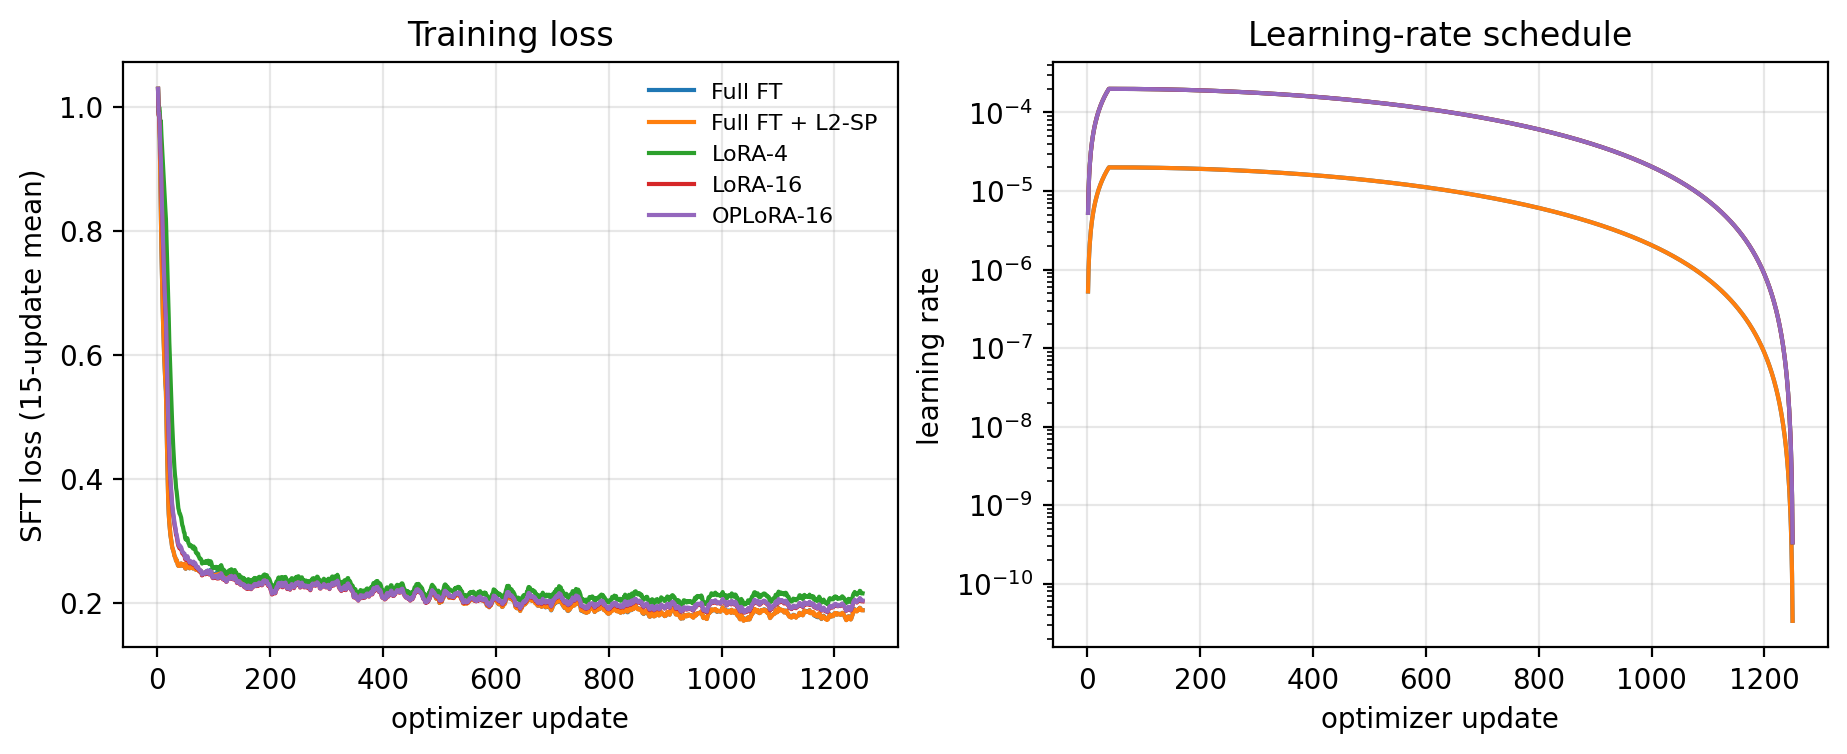

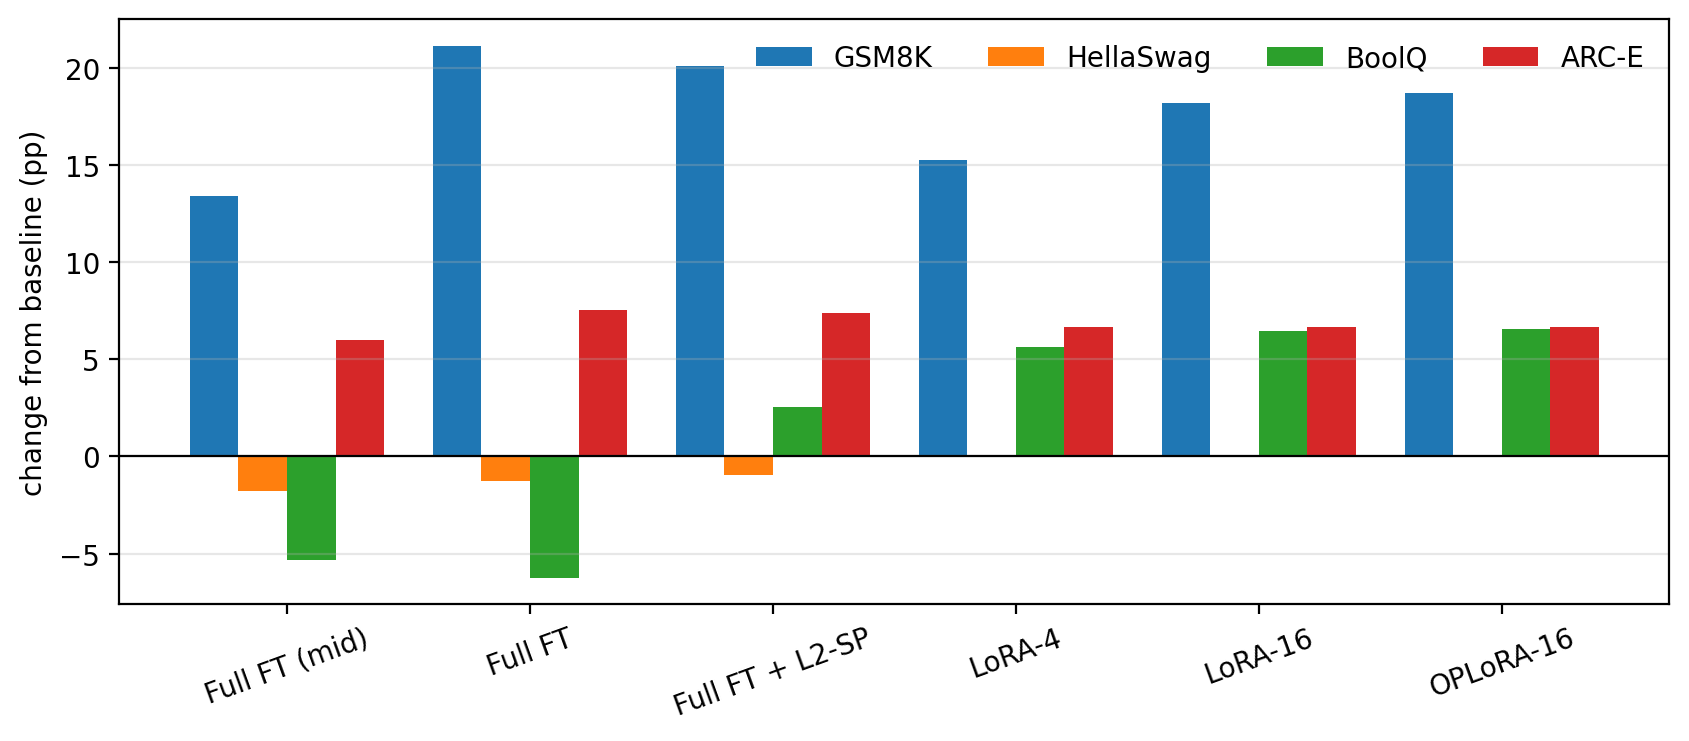

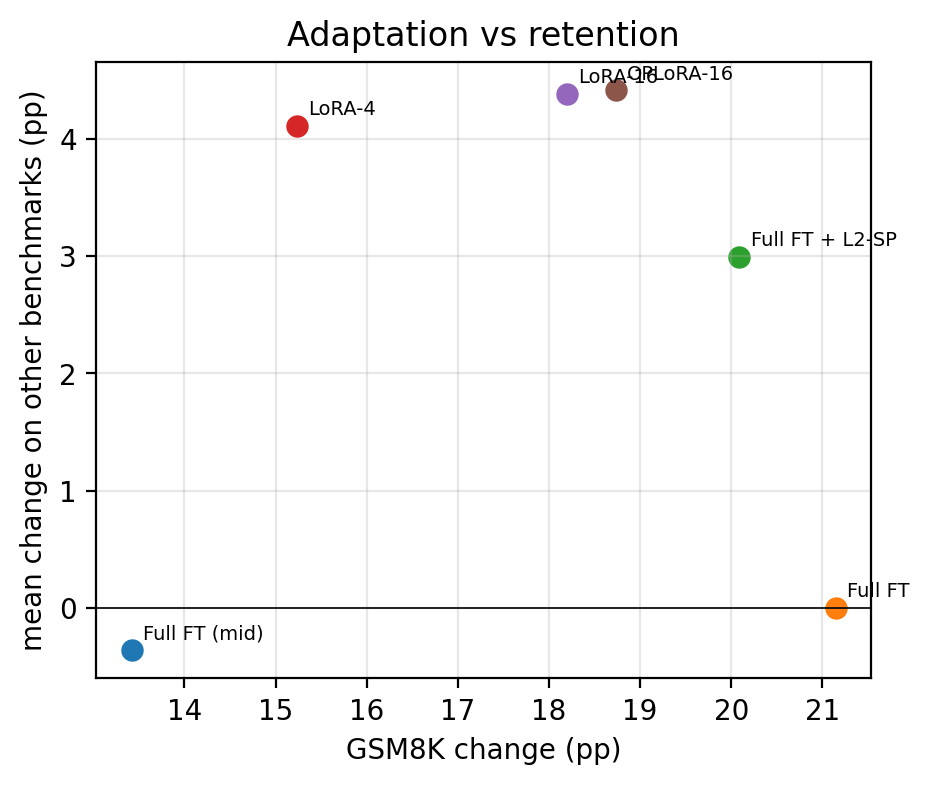

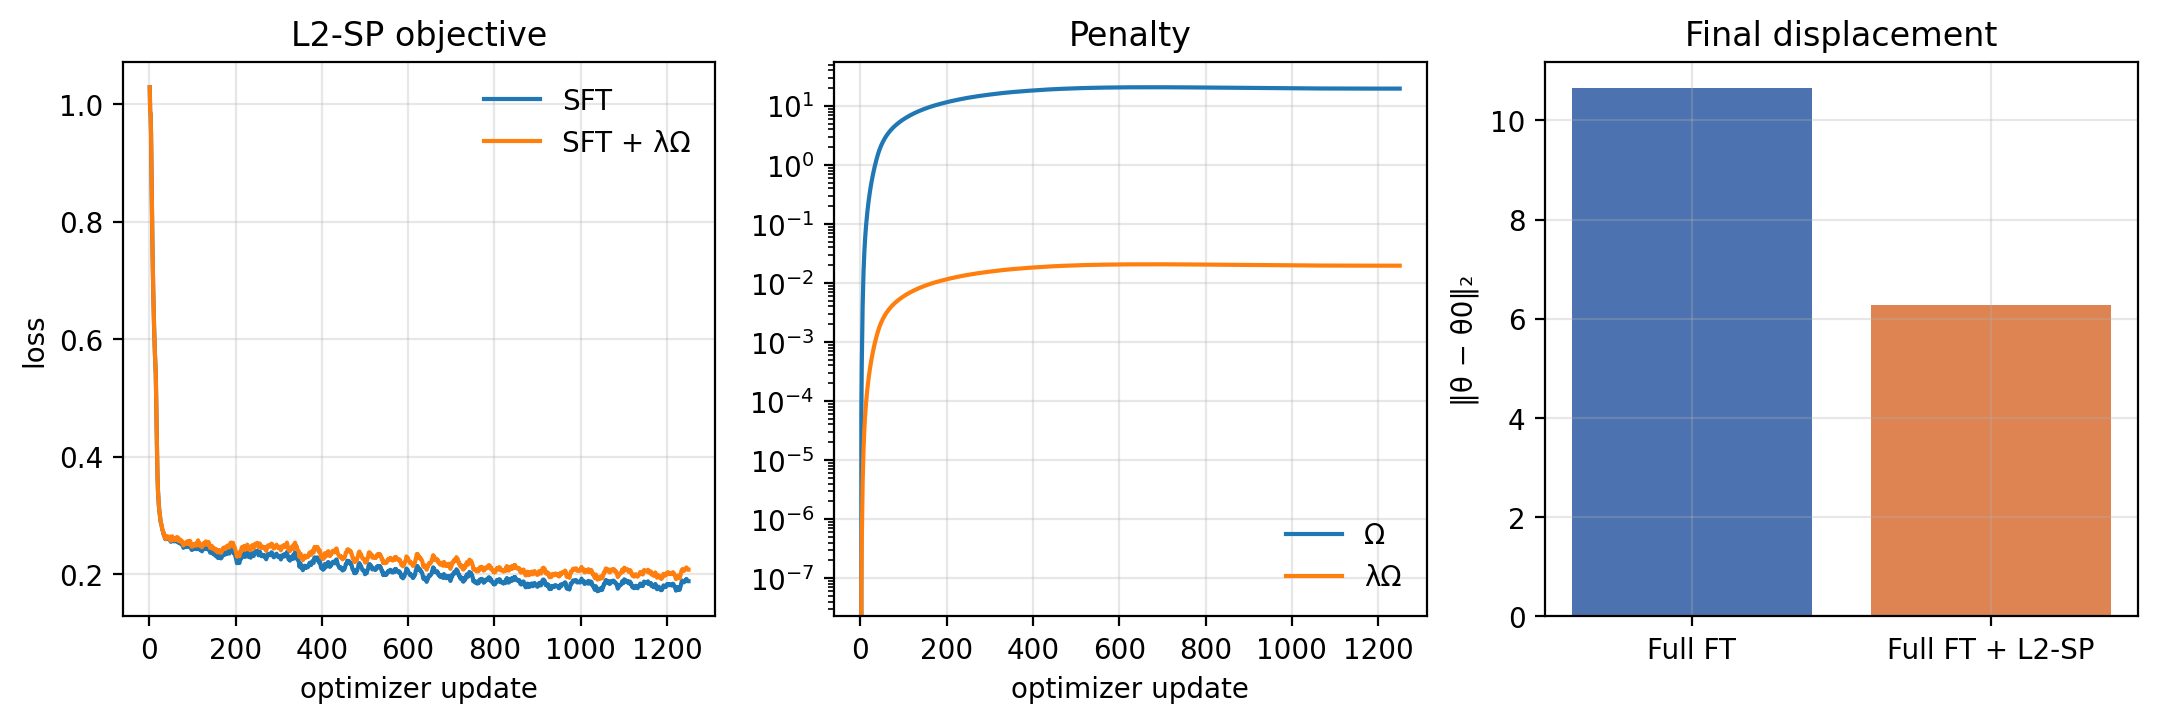

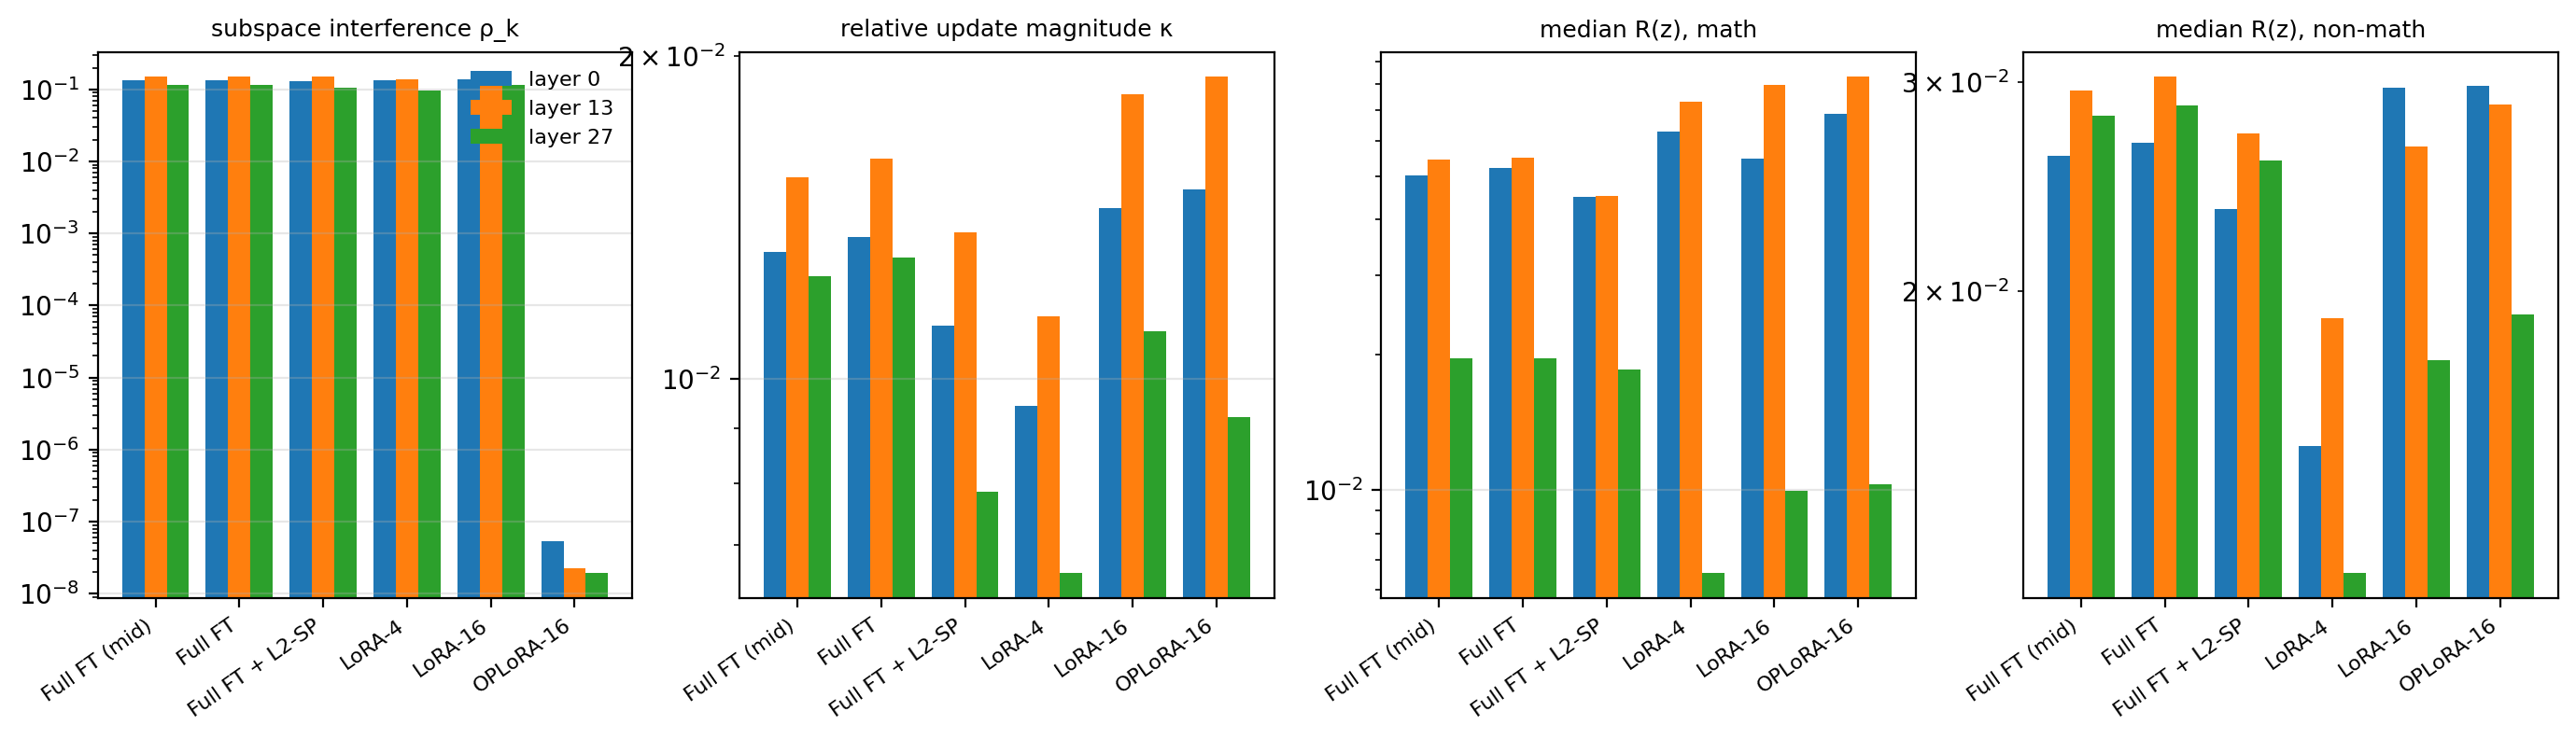

In [6]:
import pandas as pd
from IPython.display import Image, display

for t in ["benchmarks", "resources", "displacement", "diagnostics"]:
    display(pd.read_csv(f"results/task1/tables/{t}.csv"))
for f in ["loss_and_lr", "benchmark_deltas", "tradeoff", "l2sp", "diagnostics"]:
    display(Image(f"results/task1/figures/{f}.png"))